# ECE 3715 Mini-Project 3
## Random Vectors and the Multivariate Gaussian

This notebook currently contains Steps 1–3. Run from the setup cell in a fresh kernel to reproduce the tables and figures. All eight random streams are reserved here for team integration.

In [1]:
from pathlib import Path
from time import perf_counter

START_TIME = perf_counter()

import csv
import json
import platform

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import scipy
from scipy.integrate import dblquad, quad, simpson
from scipy.special import ndtri
from scipy.stats import linregress

from mp3lib import is_valid_covariance, sample_mean_cov

SEED = 1015518633  # drawn 2026-11-10, do not change
rng = np.random.default_rng(SEED)
rng1, rng2, rng3, rng4, rng5, rng6, rng7, rng8 = rng.spawn(8)

FIGURES = Path("figures")
RESULTS = Path("results")
FIGURES.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 160,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "legend.fontsize": 8,
})

def save_table(name, rows):
    with (RESULTS / f"{name}.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)

def show_and_save(fig, number):
    fig.savefig(FIGURES / f"figure_{number:02d}.png", bbox_inches="tight")
    plt.show()
    plt.close(fig)

## Step 1 — Two variables at once

On the unit square, $f_{X,Y}(x,y)=x+y\geq 0$, and the density is zero elsewhere. The total mass is

$$\int_0^1\int_0^1 (x+y)\,dy\,dx
=\int_0^1 (x+\tfrac12)\,dx=\tfrac12+\tfrac12=1.$$

Integrating over the other coordinate gives $f_X(x)=x+\tfrac12$ and $f_Y(y)=y+\tfrac12$ on $[0,1]$. For $0\le y\le 1$,

$$f_{Y\mid X=x}(y)=\frac{x+y}{x+\tfrac12},\qquad
f_{Y\mid X=0.3}(y)=\frac{0.3+y}{0.8}.$$

The numerator integrates to $x+\tfrac12$, so the conditional density integrates to one.

For nonnegative integer powers $a,b$, direct integration gives

$$E[X^aY^b]
=\int_0^1\int_0^1 (x^{a+1}y^b+x^ay^{b+1})\,dy\,dx
=\frac{1}{(a+2)(b+1)}+\frac{1}{(a+1)(b+2)}.$$

In particular, $E[X]=E[Y]=\tfrac13+\tfrac14=\tfrac7{12}$, $E[XY]=\tfrac16+\tfrac16=\tfrac13$, and $E[X^2]=E[Y^2]=\tfrac14+\tfrac16=\tfrac5{12}$. Therefore

$$\begin{aligned}
\operatorname{Var}(X)&=\operatorname{Var}(Y)=\tfrac5{12}-(\tfrac7{12})^2=\tfrac{11}{144},\\
\operatorname{Cov}(X,Y)&=\tfrac13-(\tfrac7{12})^2=-\tfrac1{144},\\
\rho&=\frac{-1/144}{11/144}=-\tfrac1{11}.
\end{aligned}$$

For rejection sampling, propose $(U,V)$ uniformly on the unit square and accept with probability $(U+V)/2$. The proposal density is one and $x+y$ reaches its maximum of two at $(1,1)$, so two is the smallest valid envelope multiplier. Integrating the acceptance probability over the proposal gives a theoretical acceptance rate of $1/2$.

Statistic        Theory   Quadrature  Quad - theory   Simulation  Sim - theory   Std. error  Error / SE
E[X]         0.58333333   0.58333333      -1.11e-16   0.58355399     2.207e-04    2.764e-04       0.798
E[Y]         0.58333333   0.58333333      -1.11e-16   0.58317102    -1.623e-04    2.763e-04      -0.587
E[XY]        0.33333333   0.33333333       1.11e-16   0.33328252    -5.082e-05    2.356e-04      -0.216
Var(X)       0.07638889   0.07638889       5.55e-17   0.07639441     5.520e-06    7.642e-05       0.072
Var(Y)       0.07638889   0.07638889       5.55e-17   0.07635660    -3.229e-05    7.628e-05      -0.423
Cov(X,Y)    -0.00694444  -0.00694444       1.91e-16  -0.00702927    -8.482e-05    7.481e-05      -1.134
rho         -0.09090909  -0.09090909       2.58e-15  -0.09203563    -1.127e-03    9.709e-04      -1.160
Rejection sampling: 1,000,000 accepted in 1,999,459 proposals. Rate = 0.500135; theory = 0.500000; difference = +1.353e-04; approximate SE = 3.536e-04.
Joint mass = 1.0

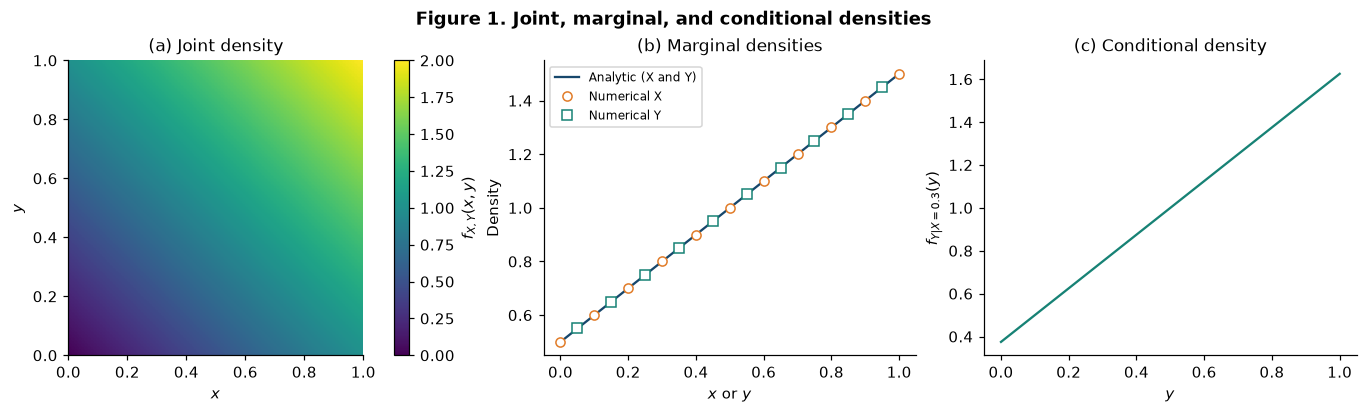

In [2]:
def joint_moment_quad(a, b):
    integral, _ = dblquad(
        lambda y, x: x**a * y**b * (x + y), 0, 1,
        lambda x: 0, lambda x: 1,
    )
    return integral

def step1_rejection_sample(n, generator):
    accepted_samples = np.empty((n, 2))
    filled = proposed = 0
    while filled < n:
        batch = generator.random((250_000, 3))
        accepted_indices = np.flatnonzero(2 * batch[:, 2] < batch[:, 0] + batch[:, 1])
        used = min(n - filled, accepted_indices.size)
        accepted_samples[filled:filled + used] = batch[accepted_indices[:used], :2]
        filled += used
        # Count proposals only through the last retained acceptance.
        proposed += int(accepted_indices[used - 1]) + 1 if filled == n else len(batch)
    return accepted_samples, proposed

def step1_compare():
    names = ("E[X]", "E[Y]", "E[XY]", "Var(X)", "Var(Y)", "Cov(X,Y)", "rho")
    theory = np.array([7/12, 7/12, 1/3, 11/144, 11/144, -1/144, -1/11])
    ex, ey, exy, ex2, ey2 = (
        joint_moment_quad(a, b) for a, b in [(1, 0), (0, 1), (1, 1), (2, 0), (0, 2)]
    )
    vx, vy, cxy = ex2 - ex**2, ey2 - ey**2, exy - ex * ey
    quadrature = [ex, ey, exy, vx, vy, cxy, cxy / np.sqrt(vx * vy)]

    n = 10**6
    samples, proposals = step1_rejection_sample(n, rng1)
    x, y = samples.T
    mean, cov = sample_mean_cov(samples)
    vx, vy, cxy = cov[0, 0], cov[1, 1], cov[0, 1]
    rho = cxy / np.sqrt(vx * vy)
    estimate = [*mean, np.mean(x * y), vx, vy, cxy, rho]

    # Plug-in influence scores for the means, raw moment, variances, covariance,
    # and the correlation delta method. Centering by sample means is intentional.
    xc, yc = x - mean[0], y - mean[1]
    xx, yy, xy = xc**2, yc**2, xc * yc
    rho_score = xy / np.sqrt(vx * vy) - 0.5 * rho * (xx / vx + yy / vy)
    scores = (x, y, x * y, xx, yy, xy, rho_score)
    errors = [np.std(score, ddof=1) / np.sqrt(n) for score in scores]

    rows = []
    print(f"{'Statistic':<10} {'Theory':>12} {'Quadrature':>12} {'Quad - theory':>14}"
          f" {'Simulation':>12} {'Sim - theory':>13} {'Std. error':>12} {'Error / SE':>11}")
    for name, exact, numeric, observed, se in zip(names, theory, quadrature, estimate, errors):
        delta = observed - exact
        print(f"{name:<10} {exact:12.8f} {numeric:12.8f} {numeric-exact:14.2e}"
              f" {observed:12.8f} {delta:13.3e} {se:12.3e} {delta/se:11.3f}")
        rows.append(dict(statistic=name, theory=exact, quadrature=numeric,
                         quadrature_minus_theory=numeric-exact, simulation=observed,
                         simulation_minus_theory=delta, standard_error=se, error_in_se=delta/se))
    save_table("step1_moments", rows)

    rate = n / proposals
    se_rate = np.sqrt(0.5 * (1 - 0.5) / proposals)
    print(f"Rejection sampling: {n:,} accepted in {proposals:,} proposals. "
          f"Rate = {rate:.6f}; theory = 0.500000; difference = {rate-0.5:+.3e}; "
          f"approximate SE = {se_rate:.3e}.")
    save_table("step1_acceptance", [dict(samples=n, proposals=proposals, rate=rate,
                                       theory=0.5, difference=rate-0.5, standard_error=se_rate)])

step1_compare()

grid1 = np.linspace(0, 1, 201)
xx1, yy1 = np.meshgrid(grid1, grid1)
joint1 = xx1 + yy1
fx_numeric = simpson(joint1, x=grid1, axis=0)
fy_numeric = simpson(joint1, x=grid1, axis=1)
x_condition = 0.3
fx_at_condition = x_condition + 0.5
conditional1 = (x_condition + grid1) / fx_at_condition
joint_mass = joint_moment_quad(0, 0)
conditional_mass, _ = quad(lambda y: (x_condition + y) / fx_at_condition, 0, 1)
fx_max_error = np.max(np.abs(fx_numeric - (grid1 + 0.5)))
fy_max_error = np.max(np.abs(fy_numeric - (grid1 + 0.5)))
print(f"Joint mass = {joint_mass:.12f} (difference {joint_mass-1:+.2e}); "
      f"conditional mass at x = {x_condition:.1f} = {conditional_mass:.12f} "
      f"(difference {conditional_mass-1:+.2e}); f_X({x_condition:.1f}) = {fx_at_condition:.1f}.")
print(f"Maximum marginal errors on the grid: X = {fx_max_error:.2e}, Y = {fy_max_error:.2e}.")
save_table("step1_density_checks", [
    dict(check="joint mass", theory=1, numerical=joint_mass, difference=joint_mass-1),
    dict(check="conditional mass", theory=1, numerical=conditional_mass, difference=conditional_mass-1),
    dict(check="X marginal maximum error", theory=0, numerical=fx_max_error, difference=fx_max_error),
    dict(check="Y marginal maximum error", theory=0, numerical=fy_max_error, difference=fy_max_error),
])

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.65), layout="constrained")
fig.suptitle("Figure 1. Joint, marginal, and conditional densities", fontweight="bold")
joint_image = axes[0].pcolormesh(grid1, grid1, joint1, cmap="viridis", shading="auto")
fig.colorbar(joint_image, ax=axes[0], label=r"$f_{X,Y}(x,y)$")
axes[0].set(xlabel="$x$", ylabel="$y$", title="(a) Joint density", aspect="equal",
            xlim=(0, 1), ylim=(0, 1))
axes[1].plot(grid1, grid1 + 0.5, color="#17476c", label="Analytic (X and Y)")
axes[1].plot(grid1[::20], fx_numeric[::20], "o", mfc="white", color="#e17c29",
             label="Numerical X")
axes[1].plot(grid1[10::20], fy_numeric[10::20], "s", mfc="white", color="#178275",
             label="Numerical Y")
axes[1].set(xlabel="$x$ or $y$", ylabel="Density", title="(b) Marginal densities")
axes[1].legend()
axes[2].plot(grid1, conditional1, color="#178275")
axes[2].set(xlabel="$y$", ylabel=r"$f_{Y|X=0.3}(y)$", title="(c) Conditional density")
show_and_save(fig, 1)

The joint heatmap is brightest near the upper-right corner, and its symmetry explains why the marginal curves coincide. For small $X$, the $x+y$ weighting suppresses low $Y$ much more than high $Y$. As $X$ increases, the added constant flattens the conditional density, pulling the conditional mean of $Y$ downward and giving a small negative correlation.

## Step 2 — Uncorrelated does not mean independent

For $X\sim \mathrm{Uniform}(-1,1)$, symmetry gives $E[X]=E[X^3]=0$, and

$$E[X^{2k}]=\tfrac12\int_{-1}^1 x^{2k}\,dx=\frac{1}{2k+1}.$$

With $Y=X^2$, we have $E[Y]=\operatorname{Var}(X)=1/3$ and
$\operatorname{Var}(Y)=E[X^4]-E[X^2]^2=1/5-1/9=4/45$. It follows that

$$\operatorname{Cov}(X,Y)=E[X^3]-E[X]E[X^2]=0.$$

The correlation coefficient measures linear association, and the opposite-signed contributions from the two sides of the parabola cancel. Given the exact value $X=x$, $Y=x^2$ with certainty, so $\operatorname{Var}(Y\mid X=x)=0$.

A finite bin includes different $X$ values. For a bin centered at $m$ with half-width $h$, write $X=m+U$ where $U\sim \mathrm{Uniform}(-h,h)$ conditional on membership. Then $Y=m^2+2mU+U^2$, with $E[U]=E[U^3]=0$, so

$$\operatorname{Var}(Y\mid X\text{ in bin})
=4m^2\frac{h^2}{3}+\left(\frac{h^4}{5}-\frac{h^4}{9}\right)
=\frac{4m^2h^2}{3}+\frac{4h^4}{45}.$$

This variance tends to zero as bins narrow. We compare the binned estimates with this finite-width prediction and with the point-conditional limit.

At $\rho=0$ the first-order correlation influence is $X(Y-1/3)/\sqrt{\operatorname{Var}(X)\operatorname{Var}(Y)}$. Its variance is

$$\frac{E[X^6]-\frac23E[X^4]+\frac19E[X^2]}{(1/3)(4/45)}
=\frac{11}{7},$$

which gives the asymptotic correlation standard error $\sqrt{11/(7N)}$. The $1/\sqrt N$ scale in the handout is a useful reference.

Parabola sample size: 10,000,000; reference 1/sqrt(N) = 3.162e-04.
Statistic        Theory   Simulation  Sim - theory   Std. error  Error / SE
E[Y]         0.33333333   0.33323071    -1.026e-04    9.428e-05      -1.088
Var(X)       0.33333333   0.33323068    -1.027e-04    9.428e-05      -1.089
Var(Y)       0.08888889   0.08887612    -1.277e-05    3.005e-05      -0.425
Cov(X,Y)     0.00000000  -0.00004505    -4.505e-05    6.824e-05      -0.660
rho          0.00000000  -0.00026177    -2.618e-04    3.964e-04      -0.660
Bin width = 0.020. Maximum binned variance = 1.313e-04; largest bin SE = 3.708e-07; maximum absolute difference from finite-width theory = 6.359e-07.


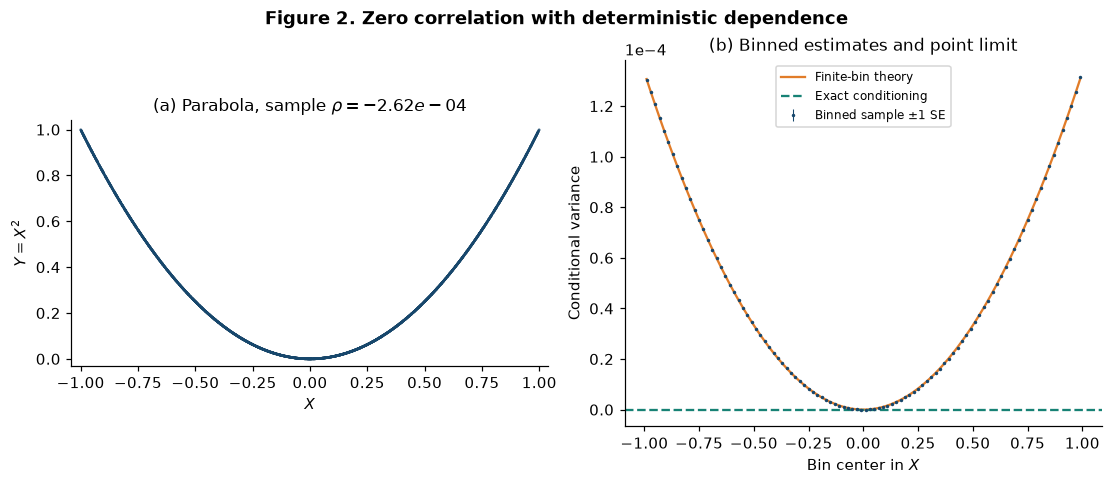

In [3]:
def step2_parabola(n, generator):
    edges = np.linspace(-1, 1, 101)
    centers = (edges[:-1] + edges[1:]) / 2
    half_width = (edges[1] - edges[0]) / 2
    bin_mean = centers**2 + half_width**2 / 3
    bin_theory = 4 * centers**2 * half_width**2 / 3 + 4 * half_width**4 / 45
    bin_count = np.zeros(centers.size, dtype=np.int64)
    bin_sums = np.zeros((3, centers.size))
    raw_sums = np.zeros(4)
    scatter = []

    for offset in range(0, n, 250_000):
        x = generator.uniform(-1, 1, min(250_000, n - offset))
        y = x**2
        raw_sums += [x.sum(), y.sum(), np.dot(x, y), np.dot(y, y)]
        index = np.searchsorted(edges[1:-1], x, side="right")
        residual = y - bin_mean[index]
        residual_sq = residual**2
        bin_count += np.bincount(index, minlength=centers.size)
        for sums, value in zip(bin_sums, (residual, residual_sq, residual_sq**2)):
            sums += np.bincount(index, weights=value, minlength=centers.size)
        scatter.append(x[::1000].copy())

    ex, ex2, ex3, ex4 = raw_sums / n
    vx, vy = ex2 - ex**2, ex4 - ex2**2
    cxy = ex3 - ex * ex2
    rho = cxy / np.sqrt(vx * vy)

    # Asymptotic standard errors from exact uniform moments through E[X^8].
    y_central4 = 1/9 - 4/21 + 6/(9*5) - 4/(27*3) + 1/81
    score_variances = [4/45, 4/45, y_central4 - (4/45)**2, 44/945, 11/7]
    names = ["E[Y]", "Var(X)", "Var(Y)", "Cov(X,Y)", "rho"]
    theory = [1/3, 1/3, 4/45, 0, 0]
    simulation = [ex2, vx, vy, cxy, rho]
    ses = np.sqrt(np.array(score_variances) / n)
    print(f"Parabola sample size: {n:,}; reference 1/sqrt(N) = {1/np.sqrt(n):.3e}.")
    print(f"{'Statistic':<10} {'Theory':>12} {'Simulation':>12} {'Sim - theory':>13}"
          f" {'Std. error':>12} {'Error / SE':>11}")
    rows = []
    for name, exact, estimate, se in zip(names, theory, simulation, ses):
        difference = estimate - exact
        print(f"{name:<10} {exact:12.8f} {estimate:12.8f} {difference:13.3e}"
              f" {se:12.3e} {difference/se:11.3f}")
        rows.append(dict(statistic=name, theory=exact, simulation=estimate,
                         difference=difference, standard_error=se, error_in_se=difference/se))
    save_table("step2_parabola_moments", rows)

    resid_mean, resid_second, resid_fourth = bin_sums / bin_count
    bin_var = (resid_second - resid_mean**2) * bin_count / (bin_count - 1)
    # Leading-order SE, using the empirical fourth moment about the exact bin mean.
    bin_se = np.sqrt(np.maximum(resid_fourth - resid_second**2, 0) / bin_count)
    bin_error = bin_var - bin_theory
    print(f"Bin width = {2*half_width:.3f}. Maximum binned variance = {max(bin_var):.3e}; "
          f"largest bin SE = {max(bin_se):.3e}; "
          f"maximum absolute difference from finite-width theory = {max(abs(bin_error)):.3e}.")
    save_table("step2_conditional_variance", [
        dict(x_lower=lo, x_upper=hi, center=center, samples=count,
             variance=estimate, finite_bin_theory=exact, difference=difference,
             standard_error=se, point_conditional_theory=0.0)
        for lo, hi, center, count, estimate, exact, difference, se
        in zip(edges[:-1], edges[1:], centers, bin_count, bin_var, bin_theory, bin_error, bin_se)
    ])
    return np.concatenate(scatter), rho, centers, bin_var, bin_theory, bin_se

x_plot, rho2, centers2, var2, theory2, se2 = step2_parabola(10**7, rng2)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3), layout="constrained")
fig.suptitle("Figure 2. Zero correlation with deterministic dependence", fontweight="bold")
axes[0].scatter(x_plot, x_plot**2, s=3, alpha=0.25, color="#17476c", edgecolors="none")
axes[0].set(xlabel="$X$", ylabel="$Y=X^2$", title=rf"(a) Parabola, sample $\rho={rho2:+.2e}$",
            aspect="equal", xlim=(-1.04, 1.04), ylim=(-0.03, 1.04))
axes[1].plot(centers2, theory2, color="#e17c29", label="Finite-bin theory")
axes[1].errorbar(centers2, var2, yerr=se2, fmt=".", ms=2.5, elinewidth=0.7,
                 color="#17476c", label="Binned sample ±1 SE")
axes[1].axhline(0, color="#178275", linestyle="--", label="Exact conditioning")
axes[1].set(xlabel="Bin center in $X$", ylabel="Conditional variance",
            title="(b) Binned estimates and point limit")
axes[1].ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
axes[1].legend(loc="upper center")
show_and_save(fig, 2)

The scatter lies on a parabola even though the estimated linear correlation is consistent with zero. The binned variances rise toward the edges, where the slope of $x^2$ is steeper and a fixed change in $X$ produces a larger change in $Y$. The estimates follow the finite-bin curve, which converges to the horizontal zero line as bin width goes to zero.

### Jointly Gaussian comparison

For a jointly Gaussian vector, zero covariance between the components makes the covariance matrix diagonal. The Gaussian exponent separates into a sum of one-variable terms and the determinant into a product, so the joint density factors into the marginal densities. In engineering, this factorization justifies treating decorrelated Gaussian channels as independent, while a nonlinear dependence such as the parabola can survive decorrelation in a non-Gaussian model.

To check factorization empirically, integrate the joint histogram and the product of the marginal histograms over the same grid cells. The grid uses standard-normal deciles and includes the tails. Write $A_i$ and $B_j$ for the two bin membership indicators, with marginal probabilities $p_i$ and $q_j$. Under independence the first-order error of $\widehat P_{ij}-\hat p_i\hat q_j$ has score $(A_i-p_i)(B_j-q_j)$, giving standard error $\sqrt{p_i(1-p_i)q_j(1-q_j)/N}$.

In [4]:
n_gauss2 = 10**6
gauss2 = rng2.standard_normal((n_gauss2, 2))
gauss_rho2 = np.corrcoef(gauss2, rowvar=False)[0, 1]
gauss_rho_se2 = 1 / np.sqrt(n_gauss2)
quantile_edges2 = ndtri(np.linspace(0, 1, 11))
joint_counts2, _, _ = np.histogram2d(*gauss2.T, bins=quantile_edges2)
del gauss2

joint_prob2 = joint_counts2 / n_gauss2
px2, py2 = joint_prob2.sum(axis=1), joint_prob2.sum(axis=0)
product_prob2 = np.outer(px2, py2)
difference2 = joint_prob2 - product_prob2
independence_se2 = np.sqrt(np.outer(px2 * (1 - px2), py2 * (1 - py2)) / n_gauss2)
standardized2 = difference2 / independence_se2
print(f"Gaussian sample size = {n_gauss2:,}. Sample rho = {gauss_rho2:+.6f}; "
      f"theory = 0; difference = {gauss_rho2:+.3e}; SE = {gauss_rho_se2:.3e}.")
print(f"Integrated joint versus product discrepancy: total variation = "
      f"{0.5 * np.abs(difference2).sum():.5f}; maximum cell gap = {np.abs(difference2).max():.3e}; "
      f"cell SE range = [{independence_se2.min():.3e}, {independence_se2.max():.3e}]; "
      f"RMS standardized gap = {np.sqrt(np.mean(standardized2**2)):.3f} SE.")
save_table("step2_gaussian_independence", [
    dict(x_lower=quantile_edges2[i], x_upper=quantile_edges2[i+1],
         y_lower=quantile_edges2[j], y_upper=quantile_edges2[j+1],
         joint_mass=joint_prob2[i, j], product_mass=product_prob2[i, j],
         difference=difference2[i, j], standard_error=independence_se2[i, j],
         error_in_se=standardized2[i, j])
    for i, j in np.ndindex(joint_prob2.shape)
])

Gaussian sample size = 1,000,000. Sample rho = +0.001779; theory = 0; difference = +1.779e-03; SE = 1.000e-03.
Integrated joint versus product discrepancy: total variation = 0.00338; maximum cell gap = 1.775e-04; cell SE range = [8.964e-05, 9.039e-05]; RMS standardized gap = 0.928 SE.


## Step 3 — The covariance matrix and how well you can estimate it

Use a zero-mean Gaussian vector with

$$\Sigma=
\begin{bmatrix}
4&2&1&0\\
2&5&2&1\\
1&2&3&1\\
0&1&1&2
\end{bmatrix}.$$

For $N$ sample vectors $x_i$, estimate the mean and covariance by

$$\hat\mu=\frac1N\sum_{i=1}^{N}x_i,\qquad
\widehat\Sigma=\frac1{N-1}\sum_{i=1}^N(x_i-\hat\mu)(x_i-\hat\mu)^T.$$

The error metric is $e_N=\|\widehat\Sigma-\Sigma\|_F$. At each sample size, draw one data set for the single-draw result and independent data sets for the replicated result. The error bars show one standard error of the replicate mean, $s_e/\sqrt R$, where $s_e$ is the sample standard deviation of the errors across $R$ replicates. The fitted slope comes from regressing $\log_{10}\bar e_N$ on $\log_{10}N$.

Sigma is symmetric: True
Eigenvalues: [1.264879 1.788195 3.098084 7.848841]
Determinant: 55.000000
Covariance validation (given Sigma): True (expected True)
Covariance validation (non-symmetric): False (expected False)
Covariance validation (symmetric, negative eigenvalue): False (expected False)
Covariance validation (singular positive semidefinite): True (expected True)
Covariance validation (tiny negative eigenvalue within tolerance): True (expected True)


        N Repeats  Single draw  Single - mean  Replicate SD   Mean error      Mean SE   sqrt(N)*mean  Scaled SE
      100     200     1.669485       0.141462      0.486100     1.528023     0.034372      15.280233   0.343725
    1,000     200     0.496281      -0.031030      0.174828     0.527310     0.012362      16.675021   0.390927
   10,000     100     0.193923       0.045099      0.051550     0.148825     0.005155      14.882456   0.515497
  100,000      30     0.051303       0.001208      0.016901     0.050095     0.003086      15.841382   0.975780
1,000,000      10     0.025211       0.011128      0.004094     0.014084     0.001295      14.083715   1.294747
Averaged log-log slope = -0.50931 (regression SE 0.00855); difference from -0.5 = -0.00931. Single-draw slope = -0.46276 (regression SE 0.02228).
Scaled averages range from 14.08 to 16.68.


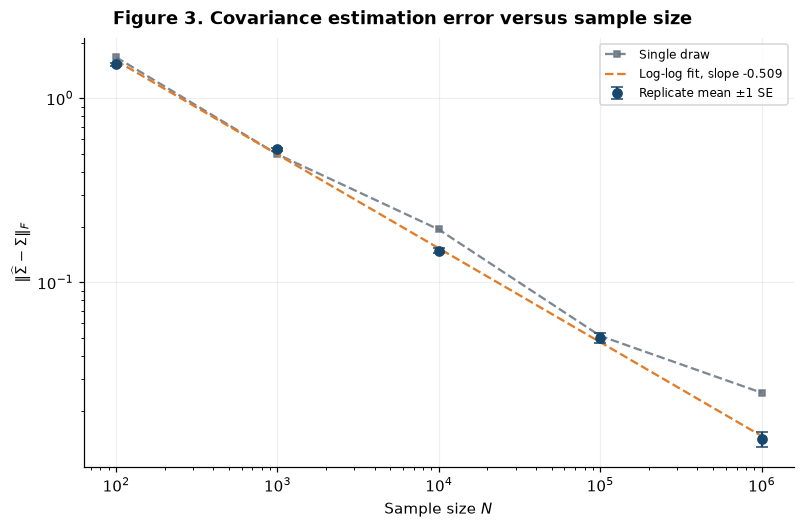

In [5]:
# Reuse this matrix for the four-dimensional whitening check in Step 6.
SIGMA_4D = np.array([
    [4, 2, 1, 0],
    [2, 5, 2, 1],
    [1, 2, 3, 1],
    [0, 1, 1, 2],
], dtype=float)
eigenvalues3, _ = np.linalg.eigh(SIGMA_4D)
det3 = np.linalg.det(SIGMA_4D)
print(f"Sigma is symmetric: {np.array_equal(SIGMA_4D, SIGMA_4D.T)}")
print(f"Eigenvalues: {np.array2string(eigenvalues3, precision=6)}")
print(f"Determinant: {det3:.6f}")

cov_cases = [
    ("given Sigma", SIGMA_4D, True),
    ("non-symmetric", [[1, 0.3], [0, 1]], False),
    ("symmetric, negative eigenvalue", [[1, 2], [2, 1]], False),
    ("singular positive semidefinite", [[1, 1], [1, 1]], True),
    ("tiny negative eigenvalue within tolerance", [[1, 0], [0, -5e-11]], True),
]
for name, matrix, expected in cov_cases:
    valid = is_valid_covariance(matrix)
    assert valid == expected, name
    print(f"Covariance validation ({name}): {valid} (expected {expected})")

save_table("step3_covariance_checks", [
    *[dict(check=f"eigenvalue {i}", value=eigenvalue)
      for i, eigenvalue in enumerate(eigenvalues3, 1)],
    dict(check="determinant", value=det3),
])

def step3_covariance_error(n):
    x = rng3.multivariate_normal(np.zeros(4), SIGMA_4D, size=n, method="cholesky")
    _, sample_cov = sample_mean_cov(x)
    return np.linalg.norm(sample_cov - SIGMA_4D, ord="fro")

sizes3 = np.array([10**2, 10**3, 10**4, 10**5, 10**6])
repeats3 = [200, 200, 100, 30, 10]
single3 = np.array([step3_covariance_error(n) for n in sizes3])
errors3 = [
    np.array([step3_covariance_error(n) for _ in range(repeats)])
    for n, repeats in zip(sizes3, repeats3)
]
average3 = np.array([values.mean() for values in errors3])
spread3 = np.array([values.std(ddof=1) for values in errors3])
se3 = spread3 / np.sqrt(repeats3)
scaled3 = np.sqrt(sizes3) * average3
scaled_se3 = np.sqrt(sizes3) * se3

fit3 = linregress(np.log10(sizes3), np.log10(average3))
single_fit3 = linregress(np.log10(sizes3), np.log10(single3))
fitted3 = 10**fit3.intercept * sizes3.astype(float)**fit3.slope

print(f"{'N':>9} {'Repeats':>7} {'Single draw':>12} {'Single - mean':>14} {'Replicate SD':>13}"
      f" {'Mean error':>12} {'Mean SE':>12} {'sqrt(N)*mean':>14} {'Scaled SE':>10}")
summary3 = []
for n, r, single, sd, average, se, scaled, scaled_se in zip(
    sizes3, repeats3, single3, spread3, average3, se3, scaled3, scaled_se3
):
    print(f"{n:9,d} {r:7d} {single:12.6f} {single-average:14.6f} {sd:13.6f}"
          f" {average:12.6f} {se:12.6f} {scaled:14.6f} {scaled_se:10.6f}")
    summary3.append(dict(sample_size=n, repetitions=r, single_draw_error=single,
                         single_minus_average=single-average, replicate_sd=sd,
                         mean_error=average, mean_standard_error=se,
                         scaled_mean_error=scaled, scaled_standard_error=scaled_se))
save_table("step3_covariance_convergence", summary3)

slope_difference3 = fit3.slope + 0.5
print(f"Averaged log-log slope = {fit3.slope:.5f} (regression SE {fit3.stderr:.5f}); "
      f"difference from -0.5 = {slope_difference3:+.5f}. "
      f"Single-draw slope = {single_fit3.slope:.5f} (regression SE {single_fit3.stderr:.5f}).")
print(f"Scaled averages range from {scaled3.min():.2f} to {scaled3.max():.2f}.")
save_table("step3_covariance_fits", [
    dict(series="averaged", slope=fit3.slope, standard_error=fit3.stderr,
         difference_from_minus_half=slope_difference3),
    dict(series="single draw", slope=single_fit3.slope, standard_error=single_fit3.stderr,
         difference_from_minus_half=single_fit3.slope+0.5),
])

fig, ax = plt.subplots(figsize=(7.2, 4.7), layout="constrained")
fig.suptitle("Figure 3. Covariance estimation error versus sample size", fontweight="bold")
ax.plot(sizes3, single3, "s--", ms=4, color="#667380", label="Single draw", alpha=0.85)
ax.plot(sizes3, fitted3, "--", color="#e17c29", label=f"Log-log fit, slope {fit3.slope:.3f}")
ax.errorbar(sizes3, average3, yerr=se3, fmt="o", capsize=4, color="#17476c",
            label="Replicate mean ±1 SE")
ax.set(xscale="log", yscale="log", xlabel="Sample size $N$",
       ylabel=r"$\Vert\widehat{\Sigma}-\Sigma\Vert_F$")
ax.set_xticks(sizes3)
ax.grid(True, which="major", alpha=0.2)
ax.legend()
show_and_save(fig, 3)

The replicate means follow a power law close to $N^{-1/2}$, and multiplying each mean by $\sqrt N$ makes the values approximately constant. The individual draws fluctuate because each covariance estimate depends on the particular sample it sees, which makes a slope fitted to a single draw at each size sensitive to those draws.

The scaled mean at $N=10^3$ is slightly above the handout's approximate range, and the mean error at the largest sample size is below its benchmark. The standard errors in the table quantify the remaining Monte Carlo variation across the finite sets of replicates.

### Scaling to a 100-element array

A symmetric $d\times d$ matrix has $d$ diagonal and $d(d-1)/2$ distinct off-diagonal parameters, for $d(d+1)/2$ total. To extrapolate relative Frobenius accuracy, use the Gaussian covariance identity
$\operatorname{Var}(\hat\Sigma_{ij})=(\Sigma_{ii}\Sigma_{jj}+\Sigma_{ij}^2)/(N-1)$.
Summing the entry variances and dividing by $\|\Sigma\|_F^2$ gives

$$
\frac{E\|\widehat\Sigma-\Sigma\|_F^2}{\|\Sigma\|_F^2}
=\frac{1+(\operatorname{tr}\Sigma)^2/\|\Sigma\|_F^2}{N-1}.
$$

This predicts the measured inverse-square-root rate for relative RMS error. The dimension factor depends on the unknown 100-dimensional covariance spectrum. For a rough estimate assume an isotropic array covariance, which makes the numerator $1+d$ and gives the largest dimension factor for a positive semidefinite matrix of dimension $d$. We match the Gaussian RMS accuracy at the four-dimensional reference sample size and report the measured mean relative error there for comparison.

A 100-element radar has thousands of covariance terms to estimate, so it can need more independent snapshots than fit within a period of stable interference. A designer can shrink the sample covariance toward a structured target to reduce estimation variance when snapshots are limited.

In [6]:
d_small, d_large = 4, 100
n_reference = 10**4
sigma_norm3 = np.linalg.norm(SIGMA_4D, ord="fro")
factor4 = 1 + (np.trace(SIGMA_4D) / sigma_norm3)**2
factor100 = 1 + d_large
relative_rms4 = np.sqrt(factor4 / (n_reference - 1))
measured_rel4 = average3[sizes3 == n_reference].item() / sigma_norm3
measured_rel_se4 = se3[sizes3 == n_reference].item() / sigma_norm3
required_n100 = int(np.ceil(1 + (n_reference - 1) * factor100 / factor4))
for d in (d_small, d_large):
    print(f"d = {d}: {d*(d+1)//2:,} free covariance parameters.")
print(f"At N = {n_reference:,}, the measured mean relative Frobenius error is "
      f"{measured_rel4:.2%} (SE {measured_rel_se4:.2%}) and the Gaussian relative RMS "
      f"error is {relative_rms4:.2%}.")
print(f"Matching that RMS accuracy with an isotropic d = {d_large} covariance "
      f"requires roughly {required_n100:,} independent snapshots.")
save_table("step3_dimension_scaling", [
    dict(reference_dimension=d_small, target_dimension=d_large, reference_samples=n_reference,
         reference_mean_relative_error=measured_rel4, reference_mean_se=measured_rel_se4,
         reference_relative_rms=relative_rms4, isotropic_target_samples=required_n100)
])

d = 4: 10 free covariance parameters.
d = 100: 5,050 free covariance parameters.
At N = 10,000, the measured mean relative Frobenius error is 1.71% (SE 0.06%) and the Gaussian relative RMS error is 1.89%.
Matching that RMS accuracy with an isotropic d = 100 covariance requires roughly 282,179 independent snapshots.


## Runtime

Keep this cell at the end of the notebook as the team adds Steps 4–8.

In [7]:
runtime = {
    "seconds": perf_counter() - START_TIME,
    "seed": SEED,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "scipy": scipy.__version__,
    "matplotlib": mpl.__version__,
}
(RESULTS / "runtime.json").write_text(json.dumps(runtime, indent=2) + "\n", encoding="utf-8")
print(f"Notebook runtime: {runtime['seconds']:.2f} seconds (limit: 300 seconds).")

Notebook runtime: 10.23 seconds (limit: 300 seconds).
